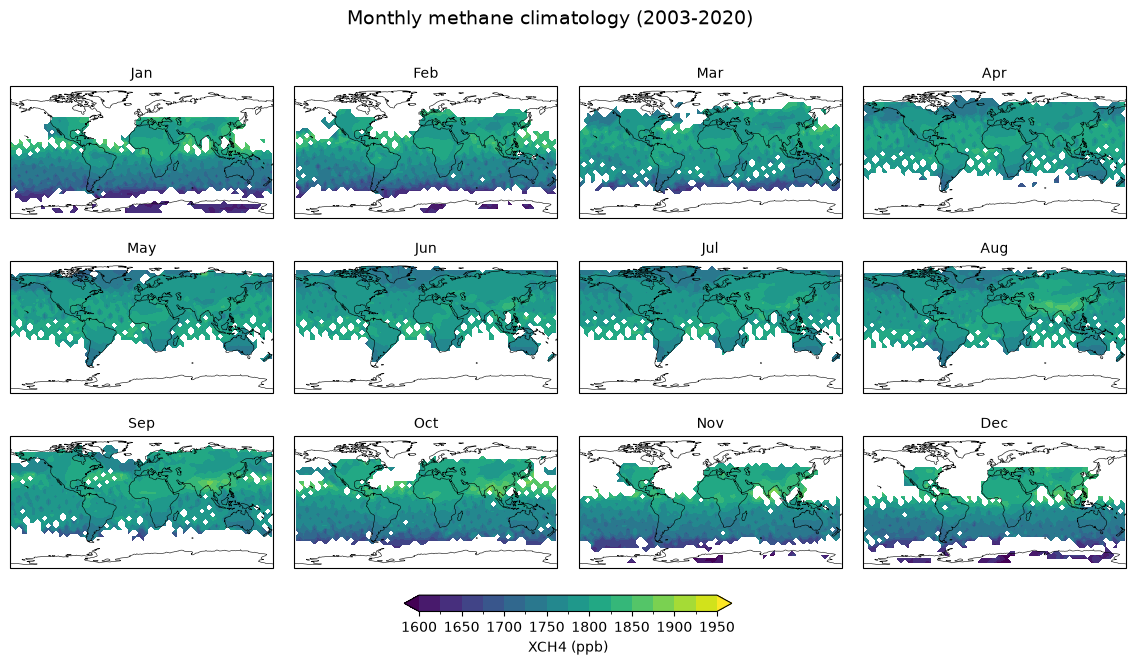

In [7]:
#1.1计算每月的甲烷气候态，并将结果绘制在多个面板中

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import xarray as xr

# 1.读取甲烷数据文件
file_name = r"C:\Users\33458\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"
ds = xr.open_dataset(file_name, engine="netcdf4")

# 填充值（缺失值）为 1e20。请将其去除（或替换），然后将单位从 mol/mol 转换为 ppb。
ch4 = ds["xch4"].where(ds["xch4"] < 1e10) * 1e9
ch4.name = "XCH4"
ch4.attrs["units"] = "ppb"

# 2.对所有年份中的每个日历月求平均值
ch4_clim = ch4.groupby("time.month").mean("time")

# 3.绘制 12 张地图
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
levels = np.arange(1600, 1951, 25)

fig, axes = plt.subplots(
    3, 4, figsize=(12, 7),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

for i, ax in enumerate(axes.flat):
    data = ch4_clim.sel(month=i + 1)
    plot = data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=levels,
        cmap="viridis",
        extend="both",
        add_colorbar=False,
    )
    ax.coastlines(linewidth=0.4)
    ax.set_global()
    ax.set_title(month_names[i], fontsize=10)

fig.suptitle("Monthly methane climatology (2003-2020)", fontsize=14)
fig.subplots_adjust(left=0.05, right=0.98, top=0.90, bottom=0.12,
                    wspace=0.08, hspace=0.15)

cbar = fig.colorbar(
    plot,
    ax=axes.ravel().tolist(),
    orientation="horizontal",
    fraction=0.03,
    pad=0.05,
)
cbar.set_label("XCH4 (ppb)")

plt.savefig("fig1_1_methane_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

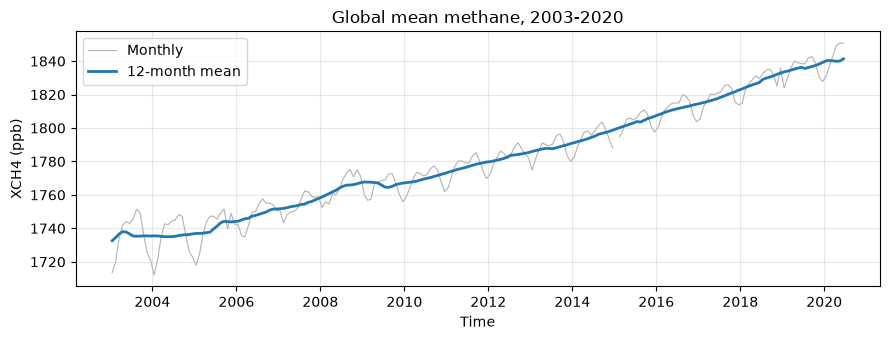

Mean XCH4 = 1781.5 ppb


In [1]:
#1.2将全球平均甲烷绘制为时间序列图。描述你的结果。（2003-01-2020-06）

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# 1.读取甲烷数据文件
file_name = r"C:\Users\33458\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"
ds = xr.open_dataset(file_name, engine="netcdf4")

# 去除填充值（缺失值），并将单位从摩尔分数（mol/mol）转换为十亿分之一（ppb）
ch4 = ds["xch4"].where(ds["xch4"] < 1e10) * 1e9
ch4.name = "XCH4"
ch4.attrs["units"] = "ppb"

# 2.进行面积加权的全球平均值。
# 极地附近的网格单元比热带网格单元小，因此我们使用 cos(纬度) 对每个纬度进行加权。
weights = np.cos(np.deg2rad(ch4["lat"]))
global_mean = ch4.weighted(weights).mean(dim=["lat", "lon"])

# 3.添加一个12个月（滑动）平均值，以便更清晰地观察长期变化。
global_mean_12 = global_mean.rolling(time=12, center=True, min_periods=6).mean()

# 4.画图
fig, ax = plt.subplots(figsize=(9, 3.5))
global_mean.plot(ax=ax, color="0.7", linewidth=0.8, label="Monthly")
global_mean_12.plot(ax=ax, color="tab:blue", linewidth=2, label="12-month mean")

ax.set_title("Global mean methane, 2003-2020")
ax.set_xlabel("Time")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("fig1_2_methane_global_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mean XCH4 =", round(float(global_mean.mean()), 1), "ppb")

#结果：全球平均甲烷浓度在2003至2020年间呈持续显著上升趋势，12个月滑动平均线有效平滑了月度数据的季节性波动，清晰地展现了长期增长。

Nearest latitude : -12.5
Nearest longitude: -147.5


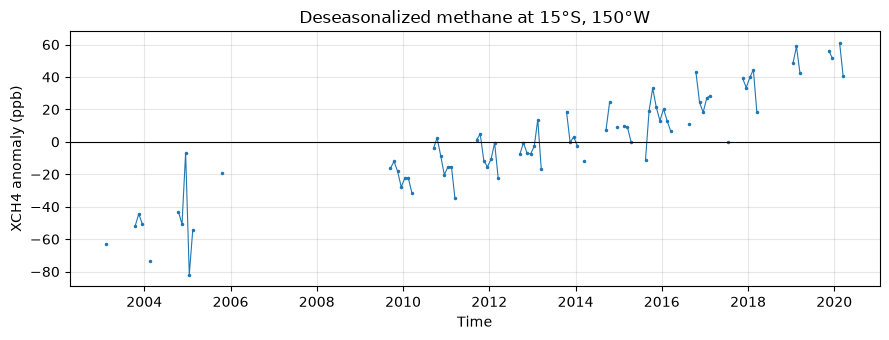

In [2]:
#1.3去季节化甲烷水平时间序列图

import matplotlib.pyplot as plt
import xarray as xr

# 1.读取甲烷数据文件
file_name = r"C:\Users\33458\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc"
ds = xr.open_dataset(file_name, engine="netcdf4")

# 去除填充值（缺失值），并将单位从摩尔分数（mol/mol）转换为十亿分之一（ppb）
ch4 = ds["xch4"].where(ds["xch4"] < 1e10) * 1e9
ch4.name = "XCH4"
ch4.attrs["units"] = "ppb"

# 2.选择距离南纬15度、西经150度最近的那个网格点
point = ch4.sel(lat=-15, lon=-150, method="nearest")
print("Nearest latitude :", float(point["lat"]))
print("Nearest longitude:", float(point["lon"]))

# 3.去除月度气候态（groupby）
point_group = point.groupby("time.month")
point_clim = point_group.mean("time")
point_anom = point_group - point_clim

# 4.绘制距平图
fig, ax = plt.subplots(figsize=(9, 3.5))
point_anom.plot(ax=ax, color="tab:blue", linewidth=0.8,
                marker=".", markersize=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Deseasonalized methane at 15°S, 150°W")
ax.set_xlabel("Time")
ax.set_ylabel("XCH4 anomaly (ppb)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig1_3_methane_point_deseasonalized.png", dpi=150, bbox_inches="tight")
plt.show()

#结果：目标区域的去季节化甲烷异常值多在-40至+40 ppb间波动，但时间序列存在明显的长时间数据断层（如2005-2009年），反映了卫星观测的局限性或数据缺失。

Nino 3.4 monthly climatology (C):
1 26.57
2 26.74
3 27.24
4 27.69
5 27.8
6 27.6
7 27.2
8 26.82
9 26.74
10 26.72
11 26.69
12 26.61


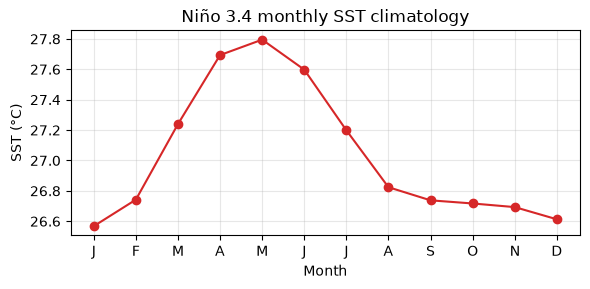

Anomaly range: -2.22 to 2.7 C


In [10]:
#2.1 计算 Niño 3.4 区域 SST 的月度气候态，并从 SST 时间序列中减去气候态以获得异常值

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# 1.读取文件
file_name = r"C:\Users\33458\NOAA_NCDC_ERSST_v3b_SST.nc"
ds = xr.open_dataset(file_name, engine="netcdf4")

# 去除填充值（-999），并仅保留海洋温度数据
sst = ds["sst"].where(ds["sst"] > -100)

# 2.选择 Niño 3.4 区域：南纬 5 度至北纬 5 度，西经 170 度至西经 120 度（西经 170 度至西经 120 度应表示为 190 度至 240 度）
nino = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))

# 3.对该区域进行面积加权平均
weights = np.cos(np.deg2rad(nino["lat"]))
nino_mean = nino.weighted(weights).mean(dim=["lat", "lon"])
nino_mean.name = "Nino34_SST"

# 4.月度气候态与距平
nino_group = nino_mean.groupby("time.month")
nino_clim = nino_group.mean("time")
nino_anom = nino_group - nino_clim

# 5.输出这12个气候态数值
print("Nino 3.4 monthly climatology (C):")
for month in range(1, 13):
    print(month, round(float(nino_clim.sel(month=month)), 2))

# 6.绘制图表
fig, ax = plt.subplots(figsize=(6, 3))
nino_clim.plot(ax=ax, color="tab:red", marker="o")
ax.set_title("Niño 3.4 monthly SST climatology")
ax.set_xlabel("Month")
ax.set_ylabel("SST (°C)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J",
                    "J", "A", "S", "O", "N", "D"])
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig2_1_nino34_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

print("Anomaly range:", round(float(nino_anom.min()), 2),
      "to", round(float(nino_anom.max()), 2), "C")

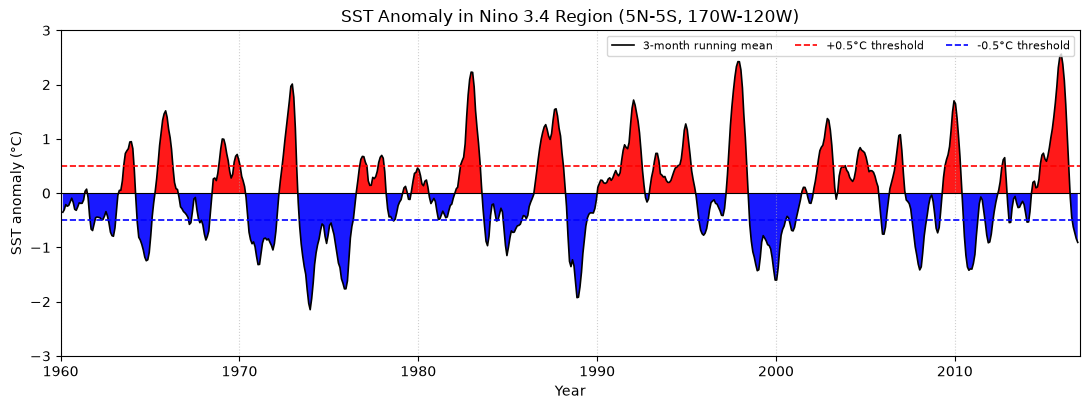

In [11]:
#2.2将计算出的 Niño 3.4 可视化

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import xarray as xr


# 1.读取文件
file_name = r"C:\Users\33458\NOAA_NCDC_ERSST_v3b_SST.nc"
ds = xr.open_dataset(file_name, engine="netcdf4")
sst = ds["sst"].where(ds["sst"] > -100)

# 2.选择 Niño 3.4 区域：南纬 5 度至北纬 5 度，西经 170 度至西经 120 度（西经 170 度至西经 120 度应表示为 190 度至 240 度）
nino = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))

# 3.按面积加权的区域平均
weights = np.cos(np.deg2rad(nino["lat"]))
nino_mean = nino.weighted(weights).mean(dim=["lat", "lon"])

# 4.每月气候和异常情况
nino_group = nino_mean.groupby("time.month")
nino_anom = nino_group - nino_group.mean("time")

# 5.三个月滚动平均
nino_3month = nino_anom.rolling(
    time=3, center=True, min_periods=3
).mean()


# 6.绘图
time = nino_3month["time"].values
index_3month = nino_3month.values

fig, ax = plt.subplots(figsize=(11, 4.2))

#正指数：红色；负指数：蓝色
ax.fill_between(
    time, 0, index_3month,
    where=index_3month >= 0,
    color="red",
    alpha=0.9,
    linewidth=0,
    interpolate=True,
)
ax.fill_between(
    time, 0, index_3month,
    where=index_3month <= 0,
    color="blue",
    alpha=0.9,
    linewidth=0,
    interpolate=True,
)

#3个月滚动平均
ax.plot(
    time, index_3month,
    color="black",
    linewidth=1.2,
    label="3-month running mean",
)

#零线和阈值
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2)
ax.axhline(-0.5, color="blue", linestyle="--", linewidth=1.2)

#这个文件的完整数据范围
ax.set_xlim(np.datetime64("1960-01-01"), np.datetime64("2016-12-31"))
ax.set_ylim(-3, 3)

ax.set_xticks([
    np.datetime64("1960-01-01"),
    np.datetime64("1970-01-01"),
    np.datetime64("1980-01-01"),
    np.datetime64("1990-01-01"),
    np.datetime64("2000-01-01"),
    np.datetime64("2010-01-01"),
])
ax.set_xticklabels(["1960", "1970", "1980", "1990", "2000", "2010"])

ax.set_title("SST Anomaly in Nino 3.4 Region (5N-5S, 170W-120W)")
ax.set_xlabel("Year")
ax.set_ylabel("SST anomaly (°C)")
ax.grid(axis="x", linestyle=":", alpha=0.6)

#图例
handles = [
    Line2D([0], [0], color="black", linewidth=1.2,
           label="3-month running mean"),
    Line2D([0], [0], color="red", linestyle="--", linewidth=1.2,
           label="+0.5°C threshold"),
    Line2D([0], [0], color="blue", linestyle="--", linewidth=1.2,
           label="-0.5°C threshold"),
]

ax.legend(
    handles=handles,
    loc="upper right",
    ncol=3,
    frameon=True,
    fontsize=8,
)

plt.tight_layout()
plt.savefig("fig2_2_nino34_index.png", dpi=150, bbox_inches="tight")
plt.show()

Number of files : 36
First file      : C:\Users\33458\MERRA2_400.tavgM_2d_aer_Nx.202301.nc4
Last file       : C:\Users\33458\MERRA2_400.tavgM_2d_aer_Nx.202512.nc4
Number of months: 36
Time range      : 2023-01-01T00:30:00.000000000 to 2025-12-01T00:30:00.000000000


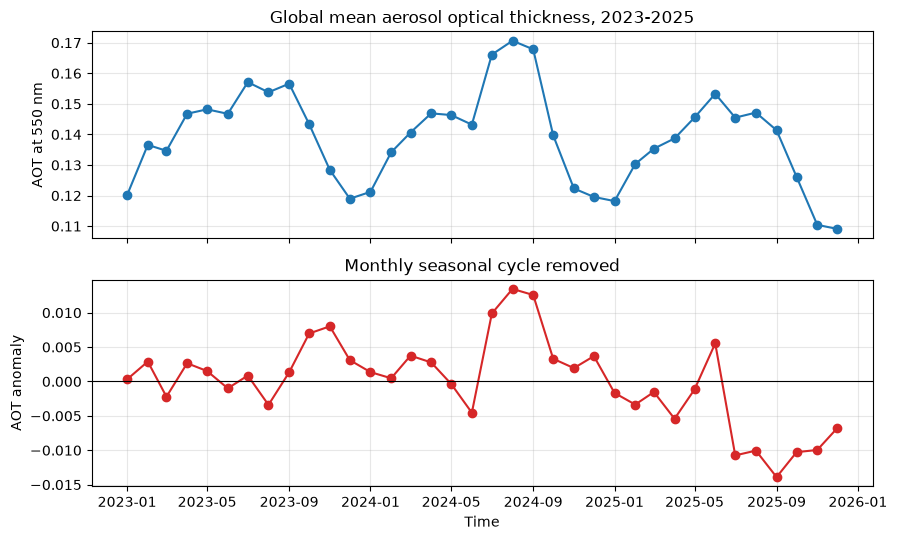

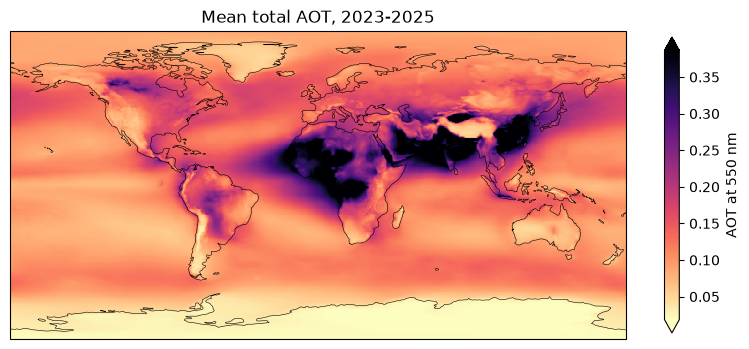

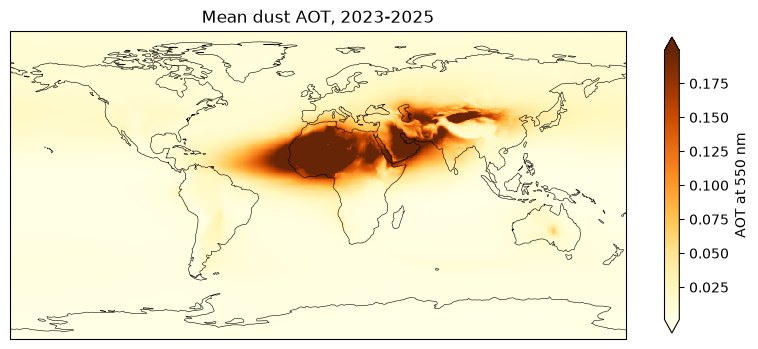

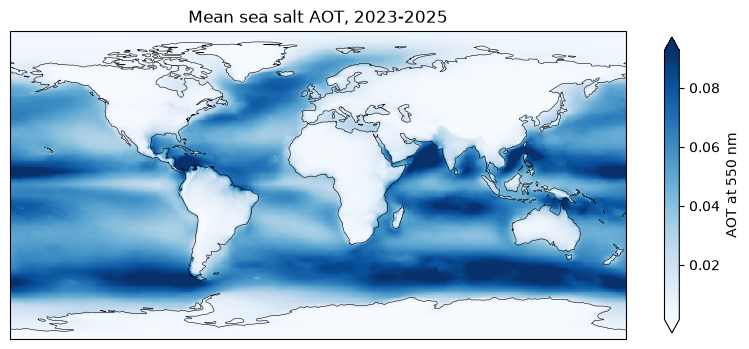

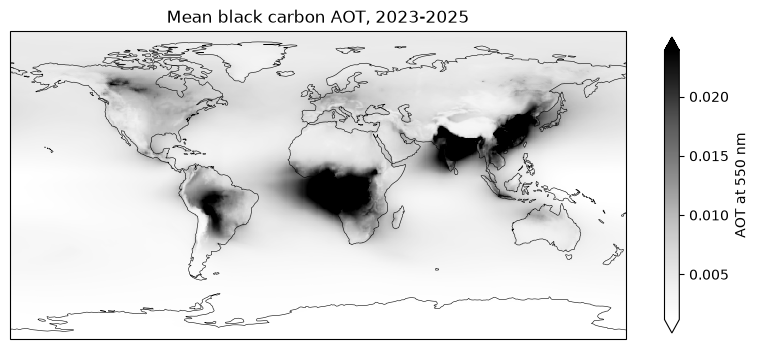

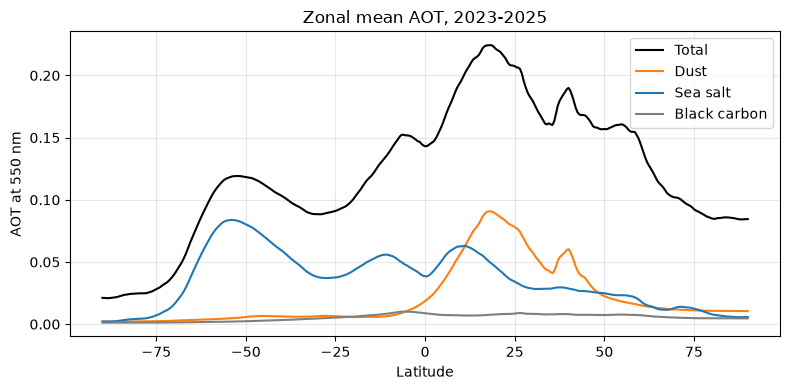

In [12]:
#3
import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# 把36个月的文件合并成一个数据集（2023-01 到 2025-12）
files = sorted(glob.glob(
    r"C:\Users\33458\MERRA2_400.tavgM_2d_aer_Nx.202[3-5]*.nc4"
))

assert len(files) == 36, f"Expected 36 files, found {len(files)}"

print("Number of files :", len(files))
print("First file      :", files[0])
print("Last file       :", files[-1])

datasets = [xr.open_dataset(f, engine="netcdf4") for f in files]
ds = xr.concat(datasets, dim="time").sortby("time")

print("Number of months:", ds.sizes["time"])
print("Time range      :", ds.time.values[0], "to", ds.time.values[-1])


# 3.1绘制一个去除月度季节循环的时间序列。

#计算面积加权
weights = np.cos(np.deg2rad(ds["lat"]))

#计算全球平均 AOT
aot = ds["TOTEXTTAU"].weighted(weights).mean(dim=["lat", "lon"])
aot.name = "Global mean AOT"

# 三年期间的月度气候概况
aot_group = aot.groupby("time.month")
aot_clim = aot_group.mean("time")
aot_anom = aot_group - aot_clim

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)

axes[0].plot(aot["time"], aot.values, "o-", color="tab:blue")
axes[0].set_ylabel("AOT at 550 nm")
axes[0].set_title("Global mean aerosol optical thickness, 2023-2025")
axes[0].grid(alpha=0.3)

axes[1].plot(aot_anom["time"], aot_anom.values, "o-", color="tab:red")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Time")
axes[1].set_ylabel("AOT anomaly")
axes[1].set_title("Monthly seasonal cycle removed")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig3_1_aot_deseasonalized.png", dpi=150,
            bbox_inches="tight")
plt.show()

# 3.2用这个数据集至少做五个不同的图表。

def plot_map(data, title, cmap, filename):
    #创建一个带有地图投影的图形
    fig = plt.figure(figsize=(8, 4))
    ax = plt.axes(projection=ccrs.PlateCarree())

    #投影
    data.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        robust=True,
        cbar_kwargs={"label": "AOT at 550 nm", "shrink": 0.8},
    )

    #添加海岸线、经纬度网格线、标签
    ax.coastlines(linewidth=0.4)
    ax.set_global()
    ax.set_title(title)

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


# Plot 1: 平均总气溶胶光学厚度
plot_map(
    ds["TOTEXTTAU"].mean("time"),
    "Mean total AOT, 2023-2025",
    "magma_r",
    "fig3_2_1_total_aot.png",
)

# Plot 2: 平均沙尘气溶胶光学厚度
plot_map(
    ds["DUEXTTAU"].mean("time"),
    "Mean dust AOT, 2023-2025",
    "YlOrBr",
    "fig3_2_2_dust_aot.png",
)

# Plot 3: 平均海盐气溶胶光学厚度
plot_map(
    ds["SSEXTTAU"].mean("time"),
    "Mean sea salt AOT, 2023-2025",
    "Blues",
    "fig3_2_3_sea_salt_aot.png",
)

# Plot 4: 平均黑碳气溶胶光学厚度
plot_map(
    ds["BCEXTTAU"].mean("time"),
    "Mean black carbon AOT, 2023-2025",
    "Greys",
    "fig3_2_4_black_carbon_aot.png",
)

# Plot 5: 纬向平均廓线
fig, ax = plt.subplots(figsize=(8, 4))

variables = [
    ("TOTEXTTAU", "black", "Total"),
    ("DUEXTTAU", "tab:orange", "Dust"),
    ("SSEXTTAU", "tab:blue", "Sea salt"),
    ("BCEXTTAU", "tab:gray", "Black carbon"),
]

for var, color, label in variables:
    ds[var].mean("time").mean("lon").plot(
        ax=ax, color=color, linewidth=1.5, label=label
    )

ax.set_title("Zonal mean AOT, 2023-2025")
ax.set_xlabel("Latitude")
ax.set_ylabel("AOT at 550 nm")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("fig3_2_5_zonal_mean_aot.png", dpi=150,
            bbox_inches="tight")
plt.show()